# JobGuard AI - Data Preprocessing and Train/Test Preparation

**Goal:** turn the raw EMSCAD file into a clean, reproducible, **leakage-safe** dataset that all four models (Logistic Regression, Naive Bayes, XGBoost, DistilBERT) will share.

**Pipeline in this notebook**

```
raw CSV -> remove duplicate rows -> fill missing text -> build combined_text
        -> remove repeated combined_text -> choose inputs (X) and target (y)
        -> stratified train/test split -> validation checks -> save train.csv and test.csv
```

**Not in this notebook:** TF-IDF, tokenizing for DistilBERT, model training, or model evaluation. We only prepare the data.

The reusable functions live in `src/preprocessing.py`. This notebook calls them step by step so every step stays visible.

## 0. Imports and paths

`train_test_split` from scikit-learn will split our data. The helper functions come from our own file `src/preprocessing.py`. Because this notebook is inside `notebooks/`, we add the project root (`..`) to Python's search path so it can find `src`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

sys.path.append("..")   # project root, so "from src..." works
from src.preprocessing import (TEXT_COLUMNS, load_data, remove_duplicates,
                               prepare_text_columns, create_combined_text,
                               count_conflicting_text, remove_duplicate_text)

RAW_PATH = Path("../data/raw/fake_job_postings.csv")
PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../results/figures")
METRICS_DIR = Path("../results/metrics")
for folder in [PROCESSED_DIR, FIGURES_DIR, METRICS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Load the real data

We load the original CSV and confirm its basic facts. Every number below is calculated by the code.

In [2]:
df_raw = load_data(RAW_PATH)

original_rows = len(df_raw)
print("Shape (rows, columns):", df_raw.shape)
print("Target column present:", "fraudulent" in df_raw.columns)
print("Target values:", sorted(df_raw["fraudulent"].unique().tolist()))
print("Legitimate postings (0):", (df_raw["fraudulent"] == 0).sum())
print("Fraudulent postings (1):", (df_raw["fraudulent"] == 1).sum())

Shape (rows, columns): (17880, 18)
Target column present: True
Target values: [0, 1]
Legitimate postings (0): 17014
Fraudulent postings (1): 866


## 2. Remove duplicate rows (first pass)

Some postings appear more than once. Every row has a different `job_id`, even when it is a copy, so we **ignore `job_id`** and compare all the other columns. We keep the **first** copy (`remove_duplicates` in `src/preprocessing.py`).

We do **not** remove rows just because some fields are empty.

> This first pass is **not enough** for a text-classification project. Section 5 explains why and adds a second, stronger step.

In [3]:
df_unique = remove_duplicates(df_raw)

rows_after_row_dedup = len(df_unique)
row_copies_removed = original_rows - rows_after_row_dedup

print("Rows before duplicate removal:", original_rows)
print("Duplicate copies removed:     ", row_copies_removed)
print("Rows after duplicate removal: ", rows_after_row_dedup)

Rows before duplicate removal: 17880
Duplicate copies removed:      281
Rows after duplicate removal:  17599


## 3. Handle missing text

Several text columns have missing values (for example `benefits` is missing for many postings). We replace each missing value with an **empty string** (`""`) instead of deleting the row.

**Why is this safer than dropping rows?**
- Deleting rows would throw away a lot of data. Thousands of postings lack at least one text field.
- It would also remove fraudulent postings, which are already rare.
- A missing field can itself be informative. In the exploration notebook we saw that fraudulent postings are missing `company_profile` far more often than legitimate ones. An empty string keeps that signal.

In [4]:
print("Missing values BEFORE filling:")
print(df_unique[TEXT_COLUMNS].isna().sum())

df_filled = prepare_text_columns(df_unique)

print()
print("Missing values AFTER filling:")
print(df_filled[TEXT_COLUMNS].isna().sum())
print()
print("Rows still present (none dropped):", len(df_filled) == len(df_unique))

Missing values BEFORE filling:
title                 0
company_profile    3282
description           1
requirements       2649
benefits           7108
dtype: int64

Missing values AFTER filling:
title              0
company_profile    0
description        0
requirements       0
benefits           0
dtype: int64

Rows still present (none dropped): True


## 4. Create `combined_text`

The models read **one** text field per posting. We join the five text columns and put a short label in front of each part, so the text stays readable and it is clear which part is which:

```
TITLE: ...
COMPANY PROFILE: ...
DESCRIPTION: ...
REQUIREMENTS: ...
BENEFITS: ...
```

We keep it light on purpose. No stemming, no lemmatization, and we do not remove punctuation or stop words. Models such as DistilBERT work best with natural text, and the simpler models can still learn from it.

In [5]:
df_filled["combined_text"] = create_combined_text(df_filled)

# Show one real posting that has no benefits, to see how missing text looks
example = df_filled[df_filled["benefits"] == ""].iloc[0]
print(example["combined_text"][:700])
print("...")

TITLE: Marketing Intern
COMPANY PROFILE: We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors in the country; we also publish well-known professionals like Mario Batali, Gwyneth Paltrow, and Danny Meyer. And we have partnerships with Whole Foods Market and Random Hous
...


## 5. Remove repeated `combined_text` (the leakage fix)

### Why removing duplicate *rows* was not enough

Step 2 removes a posting only when **every column** matches another posting. But two postings can contain **exactly the same text** and still differ in **metadata** such as `location`, `department`, or `salary_range`. A company often posts the same job ad again for another city, for example.

The cell below finds such twins in our data and shows how they differ.

In [6]:
# Postings whose combined_text appears more than once
repeated_text_rows = df_filled[df_filled["combined_text"].duplicated(keep=False)]

# Show the first repeated text: same text, but which other columns differ?
first_repeated_text = repeated_text_rows["combined_text"].iloc[0]
twins = repeated_text_rows[repeated_text_rows["combined_text"] == first_repeated_text]
twins[["job_id", "title", "location", "department", "salary_range", "fraudulent"]]

,job_id,title,location,department,salary_range,fraudulent
17,18,Southend-on-Sea Traineeships Under NAS 16-18 Y...,"GB, SOS, Southend-on-Sea",NaN,NaN,0
11529,11663,Southend-on-Sea Traineeships Under NAS 16-18 Y...,"GB, SOS, Southend-on-Sea",NaN,NaN,0


### Why this matters for an NLP model

Our models only read the **text**. To a model, two postings with identical text are the **same example**, no matter how their locations differ.

If we split the data randomly, one twin can land in the **training** set and the other in the **test** set. The model can then get the test posting right just by *remembering* the training copy, not by learning real patterns. The test score would look **better than it deserves**, and we would be overconfident about how the model handles brand-new job postings.

**Fix:** keep only the **first** posting for each unique `combined_text`, and do this **before** the train/test split.

### Safety check first

If identical text ever has **different labels** (once legitimate, once fraudulent), we must not delete rows silently; a person should look at it. So we count those conflicts before removing anything.

In [7]:
rows_before_text_dedup = len(df_filled)
repeated_copies = int(df_filled["combined_text"].duplicated().sum())
conflicting_text_groups = count_conflicting_text(df_filled)

print("Rows before combined_text deduplication:      ", rows_before_text_dedup)
print("Repeated combined_text copies to remove:      ", repeated_copies)
print("Groups of identical text with conflicting labels:", conflicting_text_groups)

if conflicting_text_groups > 0:
    raise ValueError("Conflicting labels found - stop and review before removing anything.")

Rows before combined_text deduplication:       17599
Repeated combined_text copies to remove:       1533
Groups of identical text with conflicting labels: 0


There are no conflicts, so it is safe to remove the repeated texts. `remove_duplicate_text` (in `src/preprocessing.py`) keeps the first occurrence of each text. It also refuses to run if it ever finds a conflict.

In [8]:
df_clean = remove_duplicate_text(df_filled)

# How many removed copies were legitimate, and how many fraudulent?
removed_by_class = df_filled["fraudulent"].value_counts() - df_clean["fraudulent"].value_counts()
legitimate_copies_removed = int(removed_by_class[0])
fraudulent_copies_removed = int(removed_by_class[1])

print("Rows before:                       ", rows_before_text_dedup)
print("Repeated copies removed:           ", repeated_copies)
print("  legitimate copies removed:       ", legitimate_copies_removed)
print("  fraudulent copies removed:       ", fraudulent_copies_removed)
print("Unique-text rows remaining:        ", len(df_clean))
print("Counts add up:", rows_before_text_dedup - repeated_copies == len(df_clean)
      and legitimate_copies_removed + fraudulent_copies_removed == repeated_copies)
print()
print("Class counts after deduplication:")
print(df_clean["fraudulent"].value_counts().sort_index())
print(f"Fraudulent percentage now: {df_clean['fraudulent'].mean() * 100:.2f}%")

Rows before:                        17599
Repeated copies removed:            1533
  legitimate copies removed:        1395
  fraudulent copies removed:        138
Unique-text rows remaining:         16066
Counts add up: True

Class counts after deduplication:
fraudulent
0    15348
1      718
Name: count, dtype: int64
Fraudulent percentage now: 4.47%


How long are the final combined texts? (words separated by spaces)

In [9]:
combined_word_counts = df_clean["combined_text"].str.split().str.len()
print(combined_word_counts.describe().round(0))
print("95th percentile:", int(combined_word_counts.quantile(0.95)), "words")

count    16066.0
mean       397.0
std        202.0
min          8.0
25%        253.0
50%        371.0
75%        508.0
max       2124.0
Name: combined_text, dtype: float64
95th percentile: 771 words


Most combined texts are a few hundred words. This will matter later for DistilBERT, which can only read a limited number of tokens at a time; we will deal with that in its own milestone.

## 6. Keep selected structured features

Besides text, we keep three simple yes/no columns. In the exploration notebook they showed interesting relationships with fraud:

- `telecommuting`
- `has_company_logo`
- `has_questions`

We check that they are numeric and contain only 0 and 1. We do **not** encode the large category columns (`industry`, `function`, `employment_type`, `required_experience`, `required_education`) now. We may revisit them later if needed.

In [10]:
structured_columns = ["telecommuting", "has_company_logo", "has_questions"]

for column_name in structured_columns:
    print(f"{column_name}: dtype = {df_clean[column_name].dtype}, "
          f"values = {sorted(df_clean[column_name].unique().tolist())}, "
          f"missing = {df_clean[column_name].isna().sum()}")

telecommuting: dtype = int64, values = [0, 1], missing = 0
has_company_logo: dtype = int64, values = [0, 1], missing = 0
has_questions: dtype = int64, values = [0, 1], missing = 0


## 7. Remove `job_id` and separate inputs from the target

**Why must `job_id` never be a model input?** It is just a label that identifies a row; it has nothing to do with whether the posting is fraudulent. If fraud postings happened to be added to the website in batches, a model could learn "IDs around 12,000 are fraud". That is a pattern in how the file was built, not a real signal. It would not work for new postings, and it would make our scores misleading. So we exclude it.

We build a table that contains **only** what the models may use, plus the target:
- `combined_text` and the three yes/no columns = **inputs (X)**
- `fraudulent` = **target (y)**, kept separate so a model can never "see the answer"

In [11]:
target_column = "fraudulent"

# job_id is simply not selected here
model_data = df_clean[["combined_text"] + structured_columns + [target_column]]

X_text = model_data["combined_text"]            # text input for the NLP models
X_structured = model_data[structured_columns]   # yes/no features, kept separately for later
y = model_data[target_column]                   # what we want to predict

print("Columns in model_data:", list(model_data.columns))
print("X_text:", X_text.shape, "| X_structured:", X_structured.shape, "| y:", y.shape)

Columns in model_data: ['combined_text', 'telecommuting', 'has_company_logo', 'has_questions', 'fraudulent']
X_text: (16066,) | X_structured: (16066, 3) | y: (16066,)


## 8. Stratified train/test split

**Train/test split.** We hide part of the data from the model. The model learns from the **training set**, then we judge it on the **test set**, which it has never seen. That tells us how well it will work on new postings. Because we removed repeated texts in step 5, the test texts are genuinely different from the training texts.

**Stratification.** Splitting at random could, by bad luck, put too many fraudulent postings in one set and too few in the other. A **stratified** split makes sure both sets keep the **same percentage of each class** as the full dataset.

**Why it matters here.** Only about 5% of postings are fraudulent. With a purely random split, the test set could end up with noticeably fewer fraud examples, and then recall and precision for the fraud class would be measured on very few cases and become unreliable. Stratifying with `stratify=y` prevents that.

Settings: 20% of rows go to the test set (`test_size=0.20`), and `random_state=42` makes the split identical every time we run it.

We pass the text, the structured features, and the labels to `train_test_split` **in one call**, so they are split with exactly the same rows.

In [12]:
(X_train_text, X_test_text,
 X_train_structured, X_test_structured,
 y_train, y_test) = train_test_split(
    X_text, X_structured, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training rows:", len(X_train_text))
print("Testing rows: ", len(X_test_text))

Training rows: 12852
Testing rows:  3214


## 9. Verify the split

We count the classes in the full cleaned data, the training set, and the test set. The fraud percentages should be nearly identical in all three.

In [13]:
summary_rows = []
for split_name, labels in [("All (cleaned)", y), ("Train", y_train), ("Test", y_test)]:
    summary_rows.append({
        "split": split_name,
        "rows": len(labels),
        "legitimate": int((labels == 0).sum()),
        "fraudulent": int((labels == 1).sum()),
        "fraud_percent": round(labels.mean() * 100, 2),
    })

split_summary = pd.DataFrame(summary_rows).set_index("split")
split_summary.to_csv(METRICS_DIR / "split_summary.csv")
split_summary

,rows,legitimate,fraudulent,fraud_percent
split,,,,
All (cleaned),16066,15348,718,4.47
Train,12852,12278,574,4.47
Test,3214,3070,144,4.48


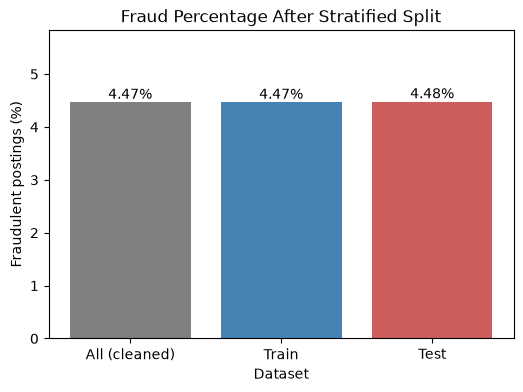

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(split_summary.index, split_summary["fraud_percent"],
              color=["gray", "steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{p:.2f}%" for p in split_summary["fraud_percent"]])
ax.set_title("Fraud Percentage After Stratified Split")
ax.set_xlabel("Dataset")
ax.set_ylabel("Fraudulent postings (%)")
ax.set_ylim(0, split_summary["fraud_percent"].max() * 1.3)
fig.savefig(FIGURES_DIR / "train_test_fraud_percentage.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Save the processed data

Each file has the columns `combined_text`, `telecommuting`, `has_company_logo`, `has_questions`, `fraudulent`. There is no `job_id`. These two files **replace** any earlier versions. Later notebooks will load them, so every model uses the **same** training and test rows.

In [15]:
train_df = pd.concat([X_train_text, X_train_structured, y_train], axis=1)
test_df = pd.concat([X_test_text, X_test_structured, y_test], axis=1)

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)

# Save the cleaning numbers for the presentation
pd.DataFrame([{
    "original_rows": original_rows,
    "rows_after_row_dedup": rows_after_row_dedup,
    "repeated_text_copies_removed": repeated_copies,
    "legitimate_copies_removed": legitimate_copies_removed,
    "fraudulent_copies_removed": fraudulent_copies_removed,
    "conflicting_text_groups": conflicting_text_groups,
    "final_unique_text_rows": len(df_clean),
}]).to_csv(METRICS_DIR / "preprocessing_summary.csv", index=False)

print("Saved:", PROCESSED_DIR / "train.csv", train_df.shape)
print("Saved:", PROCESSED_DIR / "test.csv", test_df.shape)

Saved: ../data/processed/train.csv (12852, 5)
Saved: ../data/processed/test.csv (3214, 5)


## 11. Validation checks

Before moving on, we test our own work. Each check uses `assert`, so the notebook **stops with an error** if a check fails. A line starting with `PASS` means the check succeeded.

In [16]:
# 1. No missing values in the text input or the other model columns
assert df_clean["combined_text"].isna().sum() == 0
assert model_data.isna().sum().sum() == 0
print("PASS: no missing values in combined_text or any model column")

# 2. Target contains only 0 and 1
assert set(y.unique()) == {0, 1}
print("PASS: target contains only 0 and 1")

# 3. job_id is not part of the model inputs or the processed data
assert "job_id" not in model_data.columns
assert "job_id" not in train_df.columns and "job_id" not in test_df.columns
print("PASS: job_id is not in the model inputs")

# 4. Training and testing rows do not overlap
assert len(set(X_train_text.index) & set(X_test_text.index)) == 0
assert (X_train_text.index == X_train_structured.index).all() and (X_train_text.index == y_train.index).all()
assert (X_test_text.index == X_test_structured.index).all() and (X_test_text.index == y_test.index).all()
assert len(X_train_text) + len(X_test_text) == len(model_data)
print("PASS: no row is in both train and test; text, features and labels use the same rows")

# 5. Duplicates were removed before the split: no repeated rows (ignoring job_id) and no repeated text
assert df_clean.drop(columns="job_id").duplicated().sum() == 0
assert df_clean["combined_text"].duplicated().sum() == 0
print("PASS: no duplicate rows and no repeated combined_text remain before the split")

# 6. No exact combined_text appears in both train and test (the leakage check)
overlapping_texts = set(train_df["combined_text"]) & set(test_df["combined_text"])
print("Exact combined_text values found in BOTH train and test:", len(overlapping_texts))
assert len(overlapping_texts) == 0
print("PASS: 0 overlapping combined_text values between train and test")

# 7. Class proportions are preserved by the split
overall_percent = y.mean() * 100
assert abs(y_train.mean() * 100 - overall_percent) < 0.1
assert abs(y_test.mean() * 100 - overall_percent) < 0.1
print(f"PASS: fraud % overall {overall_percent:.2f}, train {y_train.mean() * 100:.2f}, test {y_test.mean() * 100:.2f}")

# 8. The saved files load correctly and match what we saved
train_check = pd.read_csv(PROCESSED_DIR / "train.csv")
test_check = pd.read_csv(PROCESSED_DIR / "test.csv")
expected_columns = ["combined_text"] + structured_columns + [target_column]
assert list(train_check.columns) == expected_columns and list(test_check.columns) == expected_columns
assert train_check.shape == train_df.shape and test_check.shape == test_df.shape
assert train_check["combined_text"].equals(train_df["combined_text"].reset_index(drop=True))
assert test_check["combined_text"].equals(test_df["combined_text"].reset_index(drop=True))
assert train_check["fraudulent"].equals(train_df["fraudulent"].reset_index(drop=True))
assert test_check["fraudulent"].equals(test_df["fraudulent"].reset_index(drop=True))
assert train_check.isna().sum().sum() == 0 and test_check.isna().sum().sum() == 0
assert len(set(train_check["combined_text"]) & set(test_check["combined_text"])) == 0
print("PASS: saved train.csv and test.csv reload correctly, with 0 text overlap in the saved files too")

PASS: no missing values in combined_text or any model column
PASS: target contains only 0 and 1
PASS: job_id is not in the model inputs
PASS: no row is in both train and test; text, features and labels use the same rows
PASS: no duplicate rows and no repeated combined_text remain before the split
Exact combined_text values found in BOTH train and test: 0
PASS: 0 overlapping combined_text values between train and test
PASS: fraud % overall 4.47, train 4.47, test 4.48


PASS: saved train.csv and test.csv reload correctly, with 0 text overlap in the saved files too


## 12. Summary (numbers printed by code)

In [17]:
print("CLEANING")
print(f"  Original rows:                          {original_rows:,}")
print(f"  Rows after duplicate-row removal:       {rows_after_row_dedup:,}  ({row_copies_removed:,} copies removed)")
print(f"  Repeated combined_text copies removed:  {repeated_copies:,}")
print(f"    legitimate: {legitimate_copies_removed:,}   fraudulent: {fraudulent_copies_removed:,}")
print(f"  Conflicting-label text groups:          {conflicting_text_groups}")
print(f"  Final unique-text rows:                 {len(df_clean):,}")
print()
print("TEXT PREPARATION")
print("  Fields in combined_text:", ", ".join(TEXT_COLUMNS))
print("  Missing text replaced with empty strings; rows dropped for missing text:", len(df_unique) - len(df_filled))
print()
print("STRUCTURED FEATURES KEPT:", ", ".join(structured_columns))
print()
print("TRAIN/TEST SPLIT")
print(f"  Training rows: {len(train_df):,}   fraudulent: {int(y_train.sum()):,}   fraud: {y_train.mean() * 100:.2f}%")
print(f"  Testing rows:  {len(test_df):,}   fraudulent: {int(y_test.sum()):,}   fraud: {y_test.mean() * 100:.2f}%")
print()
print("LEAKAGE CHECK")
print("  Exact combined_text overlap between train and test:", len(overlapping_texts))
print()
print("FILES IN data/processed/:", sorted(p.name for p in PROCESSED_DIR.iterdir() if p.name != ".gitkeep"))

CLEANING
  Original rows:                          17,880
  Rows after duplicate-row removal:       17,599  (281 copies removed)
  Repeated combined_text copies removed:  1,533
    legitimate: 1,395   fraudulent: 138
  Conflicting-label text groups:          0
  Final unique-text rows:                 16,066

TEXT PREPARATION
  Fields in combined_text: title, company_profile, description, requirements, benefits
  Missing text replaced with empty strings; rows dropped for missing text: 0

STRUCTURED FEATURES KEPT: telecommuting, has_company_logo, has_questions

TRAIN/TEST SPLIT
  Training rows: 12,852   fraudulent: 574   fraud: 4.47%
  Testing rows:  3,214   fraudulent: 144   fraud: 4.48%

LEAKAGE CHECK
  Exact combined_text overlap between train and test: 0

FILES IN data/processed/: ['test.csv', 'train.csv']


### What we learned

- Raw data cannot go straight into a model. We removed duplicate rows, and then, because this is an **NLP** project, we also removed repeated **texts**. Postings can share identical text while differing in metadata like location, and a model that sees one copy in training and the twin in testing would only be *remembering*, not learning.
- Instead of deleting incomplete rows, we filled missing text with empty strings, so no postings (especially rare fraudulent ones) were lost.
- We built one readable `combined_text` per posting, which every model will share.
- `job_id` is only an identifier, so it was left out of the model inputs.
- A **stratified** split gave train and test sets with nearly the same fraud percentage, and the validation checks confirm that **no text appears in both sets**. Test results from now on measure performance on text the model has never seen.

**Next milestone:** convert `combined_text` into numbers with **TF-IDF** and train the first traditional model, **Logistic Regression**.